# 01 — Exploratory Data Analysis of the Raw Data

## 1. Purpose of This Notebook

This notebook examines the raw datasets acquired in Notebook 00, before any cleaning is applied. It describes
their structure and content, and identifies data quality issues. Only aggregate counts and distributions are
reported, and no information identifying an individual business is displayed.

## 2. Environment Configuration

This cell identifies the location of the data and of the copies produced in Notebook 00.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = Path('/content/drive/MyDrive/Darb DataSets')   # a shortcut to the team folder in your My Drive
    SRC_DIR = Path('/content')                                # upload the files of ml/src here
    %pip install -q python-calamine lightgbm xgboost shap
else:
    DATA_DIR = Path(os.environ.get('DARB_DATA', Path.home() / 'darb-data'))   # local copy of Darb DataSets
    SRC_DIR = Path.cwd().parent / 'src'

PIPE = DATA_DIR / 'pipeline'          # every notebook saves its results here (never in Git)
PIPE.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))


def need(path, notebook):
    """Stops with a clear message when a file from an earlier notebook is missing."""
    if not Path(path).exists():
        raise FileNotFoundError(f'{Path(path).name} not found: run {notebook} first.')
    return Path(path)


print('Colab' if IN_COLAB else 'Local', '| data:', DATA_DIR, '| results:', PIPE)

Local | data: /Users/halaalsabbar/darb-data | results: /Users/halaalsabbar/darb-data/pipeline


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

from mc_files import COLUMNS, FEW_VALUES, MAIN, BRANCH, MC_FILES, QUARTERS, column_names, standard_columns

RAW_DIR = need(PIPE / '00_raw', '00_download')
TEXT = pd.StringDtype('pyarrow')
FIGURES = SRC_DIR.parent / 'report_figures'   # figures and tables for the report (not part of the pipeline)
FIGURES.mkdir(exist_ok=True)
pd.set_option('display.width', 200)
plt.rcParams['figure.figsize'] = (11, 4)

## Part A. Ministry of Commerce Records

### A1. Structure of the Quarterly Files

The column titles of the quarterly files differ between periods. This cell maps every original title to a common
name and reports which attributes are present in each file (✓ = present).

In [3]:
present, unknown = {}, set()
for quarter, name in MC_FILES:
    titles = pq.read_schema(RAW_DIR / 'mc' / f'{name}.parquet').names
    names = column_names(quarter, name)
    unknown |= {t for t in titles if t not in names}
    present[f'{quarter} {"P1" if "PART1" in name else "P2"}'] = {names[t] for t in titles if t in names}

columns_table = pd.DataFrame({file: {c: '✓' if c in cols else '' for c in COLUMNS[2:]} for file, cols in present.items()}).T
print('Column titles without a common name:', sorted(unknown) or 'none')
columns_table

Column titles without a common name: none


,registration_number,main_registration_number,commercial_register_number,registration_type,business_name,entity_type,legal_form,registered_capital_sar,region,city,ecommerce_disclosed,founding_date
2023Q1 P1,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓
2023Q1 P2,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓
2023Q2 P1,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓
2023Q2 P2,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓
2023Q3 P1,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓
2023Q3 P2,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓
2023Q4 P1,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓
2023Q4 P2,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓
2024Q1 P1,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓
2024Q1 P2,✓,✓,,✓,✓,✓,✓,✓,✓,✓,✓,✓


**Result.** Every column title of the thirty files was mapped to a common name. The table shows that the
commercial register number exists only from 2025 Q4; the link from a branch to its main registration and the
e-commerce disclosure are absent from 2025 Q4; and part 1 of 2025 Q3 contains only five attributes.

**Interpretation.** The files can be combined under one set of attribute names, but the attributes available differ
between periods, which must be taken into account when each attribute is used.

### A2. Loading of the Quarterly Records

All quarterly files are loaded under the common column names.

In [4]:
parts = []
for quarter, name in MC_FILES:
    table = pq.read_table(RAW_DIR / 'mc' / f'{name}.parquet').to_pandas(types_mapper={pa.string(): TEXT, pa.large_string(): TEXT}.get)
    table = standard_columns(table, quarter, name)
    for column in COLUMNS:
        table[column] = table[column].astype('category' if column in FEW_VALUES else TEXT)
    parts.append(table)

mc = pd.concat(parts, ignore_index=True)
for column in FEW_VALUES:
    mc[column] = mc[column].astype('category')
del parts
print(f'Records loaded: {len(mc):,} | quarters: {mc["snapshot_quarter"].nunique()} | memory: {mc.memory_usage(deep=True).sum() / 1e9:.1f} GB')

/var/folders/r8/5bbk4r9909sf1xrdmbfz0ssr0000gn/T/ipykernel_52088/634789929.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  mc = pd.concat(parts, ignore_index=True)


/var/folders/r8/5bbk4r9909sf1xrdmbfz0ssr0000gn/T/ipykernel_52088/634789929.py:9: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  mc = pd.concat(parts, ignore_index=True)


Records loaded: 19,749,510 | quarters: 15 | memory: 3.2 GB


**Result.** The 19,749,510 records of the fifteen quarters were loaded, using 3.2 GB of memory.

**Interpretation.** All records are available for the analysis that follows; none was altered or excluded.

### A3. Number of Records per Quarter

This cell reports, for each quarter, the number of records, main registrations and branch registrations, records
without an identifier, and identifiers that appear more than once.

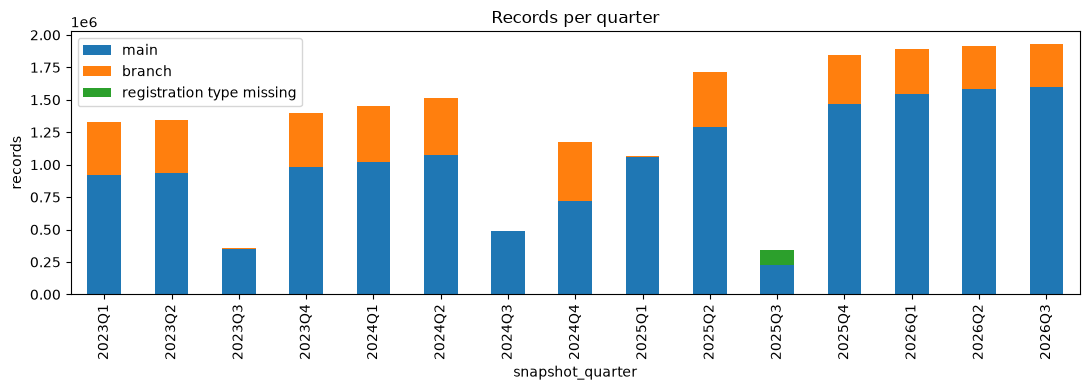

,records,main,branch,registration type missing,identifier missing,identifier repeated
snapshot_quarter,,,,,,
2023Q1,1327028,922557,404471,0,46,1
2023Q2,1341069,933668,407401,0,0,0
2023Q3,357491,347372,10119,0,0,0
2023Q4,1399410,980752,418658,0,0,0
2024Q1,1453879,1024049,429830,0,0,0
2024Q2,1511902,1071620,440282,0,0,0
2024Q3,490543,487926,2617,0,0,0
2024Q4,1171458,719712,451746,0,0,0
2025Q1,1064181,1058432,5749,0,0,0


In [5]:
rows = []
for quarter, q in mc.groupby('snapshot_quarter', observed=True):
    ids = q['registration_number'].dropna()
    rows.append({'snapshot_quarter': quarter, 'records': len(q), 'main': int((q['registration_type'] == MAIN).sum()),
                 'branch': int((q['registration_type'] == BRANCH).sum()),
                 'registration type missing': int(q['registration_type'].isna().sum()),
                 'identifier missing': int(q['registration_number'].isna().sum()), 'identifier repeated': int(ids.duplicated().sum())})
per_quarter = pd.DataFrame(rows).set_index('snapshot_quarter')

ax = per_quarter[['main', 'branch', 'registration type missing']].plot.bar(stacked=True, title='Records per quarter')
ax.set_ylabel('records'); plt.tight_layout()
for extension in ['svg', 'png']:
    plt.savefig(FIGURES / f'01_A3_records_per_quarter.{extension}', dpi=300)
plt.show()
per_quarter

**Result.** Most quarters contain between 1.1 and 1.9 million records, but 2023 Q3 (357,491), 2024 Q3 (490,543) and
2025 Q3 (338,896) contain far fewer, and 2024 Q4 (1,171,458) and 2025 Q1 (1,064,181) fewer than their neighbours.
In 2025 Q3, 109,541 records have neither a registration number nor a registration type. A registration number
appears twice in 2023 Q1 and in 2025 Q2.

**Interpretation.** Several quarterly files are incomplete. Because the files list only active registrations, a
business missing from an incomplete file would wrongly appear to have closed; this must be addressed before the
survival target is constructed. Section A11 measures how complete each quarter is.

### A4. Missing Values per Attribute and Quarter

This cell reports the percentage of missing values of each attribute in each quarter.

In [6]:
missing_share = mc.drop(columns=['snapshot_quarter', 'source_file']).isna().groupby(mc['snapshot_quarter'], observed=True).mean() * 100
missing_share.round(1).to_csv(FIGURES / '01_A4_missing_share_per_quarter.csv', encoding='utf-8-sig')
missing_share.round(1)

,registration_number,main_registration_number,commercial_register_number,registration_type,business_name,entity_type,legal_form,registered_capital_sar,region,city,ecommerce_disclosed,founding_date
snapshot_quarter,,,,,,,,,,,,
2023Q1,0.0,69.5,100.0,0.0,0.0,0.0,0.0,5.8,0.0,0.0,0.0,0.0
2023Q2,0.0,69.6,100.0,0.0,0.0,0.0,0.0,5.8,0.0,0.0,0.0,0.0
2023Q3,0.0,97.2,100.0,0.0,0.0,0.0,0.0,0.8,0.0,0.0,0.0,0.0
2023Q4,0.0,70.1,100.0,0.0,0.0,0.0,0.0,5.8,0.0,0.0,0.0,0.0
2024Q1,0.0,70.4,100.0,0.0,0.0,0.0,0.0,5.8,0.0,0.0,0.0,0.0
2024Q2,0.0,70.9,100.0,0.0,0.0,0.0,0.0,5.8,0.0,0.0,0.0,0.0
2024Q3,0.0,99.5,100.0,0.0,0.0,0.0,0.0,0.3,0.0,0.0,0.0,0.0
2024Q4,0.0,61.5,100.0,0.0,0.0,0.0,0.0,7.6,0.0,0.0,0.0,0.0
2025Q1,0.0,99.5,100.0,0.0,0.0,0.0,0.0,0.2,0.0,0.0,0.0,0.0


**Result.** Registered capital is missing for 5.8% of the records in most quarters up to 2024 Q2. In 2025 Q3,
32.3% of the records lack the registration number, registration type, legal form, region and e-commerce
disclosure. From 2025 Q4, the entity type and the e-commerce disclosure are missing entirely. The link from a
branch to its main registration is missing for about 70% of records by design, since main registrations have none.

**Interpretation.** The missing values follow the changes in the structure of the files rather than random gaps, so
each attribute is resolved according to the period in which it is missing.

### A5. Format of the Identifiers

This cell describes the length and the two leading digits of the identifiers in each quarter (formats with more
than 100 records).

In [7]:
ids = mc[['snapshot_quarter', 'registration_number']].dropna()
id_format = ids['registration_number'].str.len().astype('string') + ' digits, starting ' + ids['registration_number'].str[:2]
id_formats = pd.crosstab(id_format, ids['snapshot_quarter'])
id_formats[id_formats.sum(axis=1) > 100]

snapshot_quarter,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
registration_number,,,,,,,,,,,,,,,
"10 digits, starting 10",0,0,0,1,1,1,0,0,0,35,1,35,4,4,9856
"10 digits, starting 11",0,0,0,0,0,0,0,0,0,17,4,17,5,5,2270
"10 digits, starting 20",0,0,0,0,0,0,0,0,0,7,1,7,3,3,1476
"10 digits, starting 22",0,0,0,0,0,0,0,0,0,3,0,3,2,2,128
"10 digits, starting 25",0,0,0,0,0,0,0,0,0,2,0,2,1,1,282
"10 digits, starting 33",0,0,0,0,0,0,0,0,0,4,1,4,2,2,1128
"10 digits, starting 34",0,0,0,0,0,0,0,0,0,8,1,8,4,4,633
"10 digits, starting 35",0,0,0,0,0,0,0,0,0,2,0,2,1,1,323
"10 digits, starting 40",0,0,0,0,0,0,0,0,0,17,1,17,9,9,3588


**Result.** All registration numbers have 10 digits. Almost all start with 70; other leading digits (10, 11, 20, 40,
58 and others) appear from 2025 Q2, mostly in 2026 Q3.

**Interpretation.** The registration number keeps the same format across periods and can link a business between
quarters. The registrations with other leading digits are examined during preprocessing.

### A6. Founding Dates

This cell reports, for each quarter, the founding dates that are missing, cannot be interpreted, precede 1950, or
fall after the end of the quarter in which they are recorded.

In [8]:
day = pd.to_datetime(mc['founding_date'].str[:10], errors='coerce')
quarter_end = mc['snapshot_quarter'].astype(str).map(lambda q: pd.Period(q, 'Q').end_time.normalize())
date_checks = pd.DataFrame({
    'missing': mc['founding_date'].isna(),
    'cannot be interpreted': mc['founding_date'].notna() & day.isna(),
    'before 1950': day < '1950-01-01',
    'after the end of the quarter': day > quarter_end,
}).groupby(mc['snapshot_quarter'], observed=True).sum()
date_checks

,missing,cannot be interpreted,before 1950,after the end of the quarter
snapshot_quarter,,,,
2023Q1,0,0,2,0
2023Q2,0,0,2,0
2023Q3,0,0,1,0
2023Q4,0,0,1,0
2024Q1,0,0,1,0
2024Q2,0,0,1,0
2024Q3,0,0,1,0
2024Q4,0,0,0,0
2025Q1,0,0,0,0


**Result.** No founding date is missing. Between 107 and 150 dates per quarter cannot be interpreted from 2025 Q2,
one or two dates per quarter precede 1950, and no date falls after the end of its quarter.

**Interpretation.** The founding date is reliable for almost all records and can determine the founding quarter of
each business. A business whose founding date cannot be interpreted or precedes 1950 cannot be given a founding quarter, so it
is excluded during preprocessing.

### A7. Registered Capital

This cell reports the values of registered capital that are missing, non-numeric, zero or negative. The
distribution is described for the main registrations of the most recent quarter only, since a business appears in
every quarter in which it is active and would otherwise be counted several times.

The second table counts, for the main registrations of each quarter, the values that cannot be a real capital: an
empty value, −1, 0 and 1 SAR. The last line measures how often the capital of the same business changes between
the quarters in which it appears.

missing        504202
non-numeric         1
zero            10773
negative         3139 



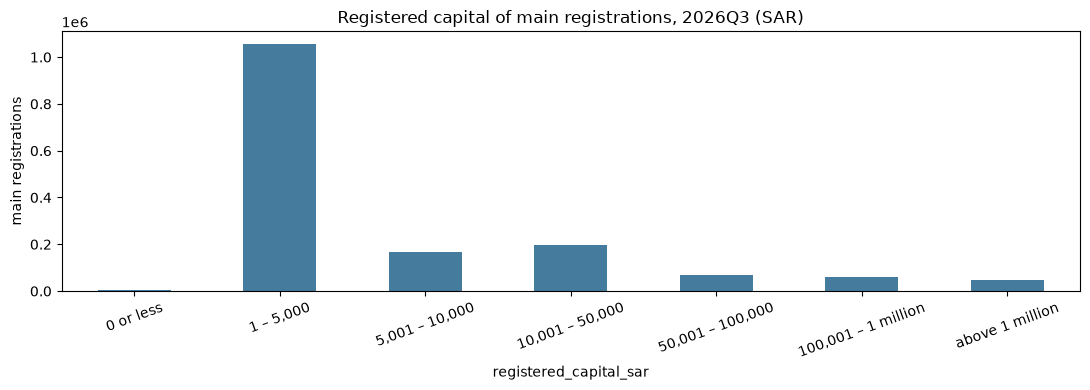

col_0            empty  −1     0      1 other negative other values
snapshot_quarter                                                   
2023Q1           1,082   0     0    135              0      921,340
2023Q2           1,090   0     0    139              0      932,439
2023Q3             636   0     0     75              0      346,661
2023Q4           1,142   0     0    145              0      979,465
2024Q1           1,182   0     0    155              0    1,022,712
2024Q2           1,235   0     0    397              0    1,069,988
2024Q3             848   0     0    307              0      486,771
2024Q4             994   0     0    314              0      718,404
2025Q1           1,305   0     0    650              0    1,056,477
2025Q2               9 609   936  3,326              0    1,282,948
2025Q3               0  16    25    363              0      228,950
2025Q4              10 476   884  7,553              0    1,459,610
2026Q1              16 411   855  9,951         

Businesses with a real capital in more than one quarter: 1,957,286 | the same capital in every quarter: 95.1%


In [9]:
capital = pd.to_numeric(mc['registered_capital_sar'].str.replace(',', '', regex=False), errors='coerce')
checks = pd.Series({'missing': int(mc['registered_capital_sar'].isna().sum()),
                    'non-numeric': int((mc['registered_capital_sar'].notna() & capital.isna()).sum()),
                    'zero': int((capital == 0).sum()), 'negative': int((capital < 0).sum())}, name='records (all quarters)')
print(checks.to_string(), '\n')

latest = (mc['snapshot_quarter'] == QUARTERS[-1]) & (mc['registration_type'] == MAIN)
RANGES = [-np.inf, 0, 5_000, 10_000, 50_000, 100_000, 1_000_000, np.inf]
LABELS = ['0 or less', '1 – 5,000', '5,001 – 10,000', '10,001 – 50,000', '50,001 – 100,000', '100,001 – 1 million', 'above 1 million']
ranges = pd.cut(capital[latest], RANGES, labels=LABELS).value_counts().reindex(LABELS)
ax = ranges.plot.bar(title=f'Registered capital of main registrations, {QUARTERS[-1]} (SAR)', color='#457b9d', rot=20)
ax.set_ylabel('main registrations'); plt.tight_layout(); plt.show()
pd.DataFrame({'main registrations': ranges, 'share': (ranges / ranges.sum()).map('{:.1%}'.format)})

main_rows = mc['registration_type'] == MAIN
amount = capital.astype('float64')
value_kind = pd.Series(np.select([amount.isna(), amount == -1, amount == 0, amount == 1, amount < 0],
                                 ['empty', '−1', '0', '1', 'other negative'], default='other values'), index=mc.index)
capital_codes = pd.crosstab(mc.loc[main_rows, 'snapshot_quarter'], value_kind[main_rows])
capital_codes = capital_codes.reindex(columns=['empty', '−1', '0', '1', 'other negative', 'other values'], fill_value=0)
capital_codes.to_csv(FIGURES / '01_A7_capital_codes_per_quarter.csv', encoding='utf-8-sig')
print(capital_codes.to_string(formatters={c: '{:,}'.format for c in capital_codes.columns}), '\n')

real = main_rows & (amount > 1)
values_per_business = amount[real].groupby(mc.loc[real, 'registration_number'], observed=True).agg(['nunique', 'size'])
several = values_per_business[values_per_business['size'] > 1]
print(f'Businesses with a real capital in more than one quarter: {len(several):,} | '
      f'the same capital in every quarter: {(several["nunique"] == 1).mean():.1%}')

**Result.** Registered capital is missing for 504,202 records, zero for 10,773 and negative for 3,139; one value is
not numeric. Among the main registrations of 2026 Q3, 66.0% have a capital of 5,000 SAR or less and 2.9% exceed
1 million SAR. Among main registrations, every negative capital is exactly −1: no other negative amount exists.
The values −1 and 0 never appear before 2025 Q2, and from 2025 Q2 they appear in every quarter (for example 609 and
936 in 2025 Q2, 366 and 4,204 in 2026 Q3). A capital of exactly 1 SAR rises from 75 to 650 records per quarter up to
2025 Q1 to between 3,326 and 12,539 from 2025 Q2. Empty values follow the opposite pattern: about 1,000 per quarter
up to 2025 Q1, and almost none from 2025 Q2. Of the 1,957,286 businesses with a real capital in more than one
quarter, 95.1% keep the same capital in every quarter.

**Interpretation.** From 2025 Q2, when the files changed format, an unknown capital is no longer left empty: it is written as −1, 0 or
1 SAR. These values are not amounts a business registered, and they must be resolved during preprocessing rather than
used as they are. Because the capital of a business almost never changes between quarters, the capital recorded in
a neighbouring quarter of the same business is a reliable source for resolving them. Capital is also highly skewed,
which must be considered when it is used.

### A8. Categorical Attributes

This cell lists the values of the categorical attributes (registration type, entity type and e-commerce
disclosure) and the number of distinct values of legal form, region and city per quarter.

In [10]:
for column in ['registration_type', 'entity_type', 'ecommerce_disclosed']:
    print(f'--- {column} ---')
    print(mc[column].value_counts(dropna=False).head(12).to_string(), '\n')
values = pd.concat({column: mc[column].value_counts(dropna=False) for column in ['registration_type', 'entity_type', 'ecommerce_disclosed']})
values.rename_axis(['attribute', 'value']).rename('records').to_csv(FIGURES / '01_A8_categorical_values.csv', encoding='utf-8-sig')
distinct = mc.groupby('snapshot_quarter', observed=True)[['legal_form', 'region', 'city']].nunique()
distinct.to_csv(FIGURES / '01_A8_distinct_values_per_quarter.csv', encoding='utf-8-sig')
distinct

--- registration_type ---
registration_type
رئيسي        15258734
فرعي          4381234
<NA>           109541
نوع السجل           1 

--- entity_type ---
entity_type
مؤسسة                     13191029
شركة                       4700107
<NA>                       1842278
فرع شركة أجنبية              13932
فرع شركة خليجية               2146
فرع مؤسسة فردية أجنبية          17
الكيان القانوني                  1 

--- ecommerce_disclosed ---


ecommerce_disclosed
0       11750120
<NA>     7688193
1         311197 



,legal_form,region,city
snapshot_quarter,,,
2023Q1,49,13,247
2023Q2,45,13,247
2023Q3,42,13,240
2023Q4,45,13,247
2024Q1,45,13,248
2024Q2,45,13,248
2024Q3,42,13,239
2024Q4,44,13,246
2025Q1,49,13,243


**Result.** The registration type contains one value "نوع السجل" and the entity type one value "الكيان القانوني",
which are column titles. The region has 13 values in every quarter except 2026 Q2, where it has 14. The legal form
takes between 40 and 53 values per quarter (13 in 2025 Q3), and the number of distinct cities rises from about 245
up to 2025 Q1 to between 1,724 and 4,726 from 2025 Q2.

**Interpretation.** One row of 2026 Q2 repeats the column titles and is not a business. The legal form is not
written consistently, and the way cities are recorded changes in 2025 Q2; both must be harmonised so that every
period uses the same values.

### A9. E-commerce Disclosure by Period

Each registration states whether the business sells online (e-commerce disclosure). This cell shows, for each
quarter, the share of records that say yes, say no, or do not report it at all.

In [11]:
ecommerce_values = mc['ecommerce_disclosed'].astype('string').map({'1': 'yes', '0': 'no'}).fillna('not reported')
ecommerce = pd.crosstab(mc['snapshot_quarter'], ecommerce_values, normalize='index').mul(100).round(1)
ecommerce = ecommerce.reindex(columns=['yes', 'no', 'not reported'], fill_value=0)
ecommerce.to_csv(FIGURES / '01_A9_ecommerce_per_quarter.csv', encoding='utf-8-sig')
ecommerce

ecommerce_disclosed,yes,no,not reported
snapshot_quarter,,,
2023Q1,2.5,97.5,0.0
2023Q2,2.6,97.4,0.0
2023Q3,2.9,97.1,0.0
2023Q4,2.7,97.3,0.0
2024Q1,2.7,97.3,0.0
2024Q2,2.7,97.3,0.0
2024Q3,2.8,97.2,0.0
2024Q4,2.4,97.6,0.0
2025Q1,2.7,97.3,0.0


**Result.** Up to 2025 Q2, every record states its e-commerce disclosure: between 1.7% and 2.9% say yes and the rest say no. In
2025 Q3, 32.3% of the records do not report it (the records of part 1, section A1). From 2025 Q4, no record reports it.

**Interpretation.** Whether the e-commerce disclosure is known depends on the period of the file, not on the business. A business that
appears for the first time from 2025 Q4 has no e-commerce value, and this absence says nothing about the business.

### A10. Branch Registrations

**What a branch is.** Until 2025, a business that opened a second shop or office in another place registered it as
a **branch** (فرعي) under its **main** registration (رئيسي). A branch is part of the same business, not a new
business. In the older files, every branch row also records the number of the main registration it belongs to.

**What changed with the law.** The new Commercial Register Law, in force since 3 April 2025 (5 Shawwal 1446 AH),
stopped issuing branch registrations: one registration now covers all the activities of a business. Existing branches
were given five years to settle their situation in one of three ways: hand the branch over to another party so that it
becomes a main registration of its own, turn it into a new company, or close it and move its activities to the main
registration ([Ministry of Commerce, 17 September 2024](https://mc.gov.sa/ar/mediacenter/News/Pages/17-09-24-01.aspx);
[Ministry of Commerce, 3 April 2025](https://mc.gov.sa/ar/mediacenter/News/Pages/03-04-25-01.aspx)).

The first table shows, for each quarter, how many branch rows there are, how many of them name their main
registration, and how often that main registration is in the same quarterly file.

In [12]:
rows = []
for quarter, q in mc.groupby('snapshot_quarter', observed=True):
    mains = set(q.loc[q['registration_type'] == MAIN, 'registration_number'].dropna())
    branches = q[q['registration_type'] == BRANCH]
    rows.append({'snapshot_quarter': quarter, 'branch rows': len(branches),
                 'name their main registration': int(branches['main_registration_number'].notna().sum()),
                 'main registration in the same file': int(branches['main_registration_number'].isin(mains).sum())})
branch_links = pd.DataFrame(rows).set_index('snapshot_quarter')
branch_links.to_csv(FIGURES / '01_A10_branch_links_per_quarter.csv', encoding='utf-8-sig')
branch_links

,branch rows,name their main registration,main registration in the same file
snapshot_quarter,,,
2023Q1,404471,404305,378028
2023Q2,407401,407236,382861
2023Q3,10119,10119,1783
2023Q4,418658,418492,398614
2024Q1,429830,429664,412389
2024Q2,440282,440117,425606
2024Q3,2617,2617,763
2024Q4,451746,451580,284717
2025Q1,5749,5749,5363


The second table follows the same registration numbers from 2025 Q2, the last file before the law, to 2025 Q4, the
first complete file after it, and counts the numbers whose registration type is different in the two files. It also
checks whether the founding date stays the same, which shows that it is the same registration and not a new one.

In [13]:
def one_quarter(quarter):
    q = mc.loc[mc['snapshot_quarter'] == quarter, ['registration_number', 'registration_type', 'main_registration_number', 'founding_date']]
    return q.dropna(subset=['registration_number']).drop_duplicates('registration_number').set_index('registration_number')

before, after, latest_q = one_quarter('2025Q2'), one_quarter('2025Q4'), one_quarter(QUARTERS[-1])
changes = {}
for label, old, new in [('branch in 2025 Q2, main in 2025 Q4', BRANCH, MAIN), ('main in 2025 Q2, branch in 2025 Q4', MAIN, BRANCH),
                        ('branch in both (for comparison)', BRANCH, BRANCH)]:
    numbers = before.index[before['registration_type'] == old].intersection(after.index[after['registration_type'] == new])
    changes[label] = {'registration numbers': len(numbers),
                      'name a main registration in 2025 Q2': int(before.loc[numbers, 'main_registration_number'].notna().sum()),
                      'same founding date in both files': int((before.loc[numbers, 'founding_date'] == after.loc[numbers, 'founding_date']).sum()),
                      f'main registration in {QUARTERS[-1]}': int((latest_q['registration_type'].reindex(numbers) == MAIN).sum())}
type_changes = pd.DataFrame(changes).T
type_changes.to_csv(FIGURES / '01_A10_branch_type_changes.csv', encoding='utf-8-sig')

linked = before[(before['registration_type'] == BRANCH)].join(before['founding_date'].rename('main_founding_date'), on='main_registration_number', how='inner')
branch_day = pd.to_datetime(linked['founding_date'].str[:10], errors='coerce')
main_day = pd.to_datetime(linked['main_founding_date'].str[:10], errors='coerce')
print(f'Branches of 2025 Q2 whose main registration is in the same file: {len(linked):,} | '
      f'founded before their main registration: {(branch_day < main_day).mean():.1%} | '
      f'median time after the main registration: {(branch_day - main_day).dt.days.median():,.0f} days')
type_changes

Branches of 2025 Q2 whose main registration is in the same file: 426,811 | founded before their main registration: 15.1% | median time after the main registration: 852 days


,registration numbers,name a main registration in 2025 Q2,same founding date in both files,main registration in 2026Q3
"branch in 2025 Q2, main in 2025 Q4",15512,15512,15512,13970
"main in 2025 Q2, branch in 2025 Q4",2215,0,2215,339
branch in both (for comparison),371528,371528,371528,19844


**Result.** Up to 2025 Q2, each complete quarter contains between 404,471 and 451,746 branch rows, and almost every one names its
main registration (for example 427,173 of 427,173 in 2025 Q2). That main registration is in the same file for
85% to 99.8% of them, except in 2024 Q4 (63%) and in the incomplete quarters. The 2025 Q3 file contains a single
branch row. From 2025 Q4, branch rows remain (373,745 in 2025 Q4, 329,467 in 2026 Q3), but none names its main
registration, because the files no longer have that column.

Between 2025 Q2 and 2025 Q4, 15,512 registrations change from branch to main. All of them named a main
registration in 2025 Q2, and all keep the same founding date, so they are the same registrations, not new ones;
13,970 are still main registrations in 2026 Q3. Of the 371,528 branches that are still branches in 2025 Q4, 19,844
have become main registrations by 2026 Q3. In the other direction, 2,215 main registrations of 2025 Q2 are recorded
as branches in 2025 Q4, with the same founding date. Among the branches of 2025 Q2 whose main registration is in the
same file, 15.1% carry a founding date earlier than that of their main registration, and the median branch was
founded 852 days after its main registration.

**Interpretation.** A branch is part of another business, so it is not counted as a business of its own. Up to 2025 Q2 the files say,
for every branch, which business it belongs to; from 2025 Q4 they still mark a row as a branch but no longer say
whose branch it is.

The change from branch to main is what the law allows: during the five-year transition, an existing branch can be
handed over and become a main registration, or be turned into a new company. Such a registration keeps the
founding date of the old branch, so it looks like a business founded years earlier that suddenly appears in 2025.
During its first year it was a branch of another business, not a business of its own, so it cannot show whether a
new business survives its first year. These registrations are excluded from the survival target during
preprocessing.

A change from main to branch is not possible under the new law, which no longer issues branch registrations. The
2,215 main registrations recorded as branches in 2025 Q4 are therefore treated as a recording error of that file and
are kept as main registrations during preprocessing.

A branch founded before its own main registration is possible when the main registration was re-issued later, but
the records do not show why; this does not affect the businesses, since branches are not counted as businesses.

### A11. Completeness of Each Quarterly File

The files list the registrations that are **active** at the end of each quarter. A registration that is active in a
quarter and was already founded before an earlier quarter ended should therefore also appear in that earlier quarter.
This cell takes the main registrations of each quarter that were founded before the previous quarter ended, and
measures what share of them is found in the previous quarter's file. A share close to 100% means the earlier file is
complete; a low share means many active businesses are missing from it.

A business missing from an incomplete file would wrongly look closed in that quarter. How preprocessing resolves
this is explained after the result.

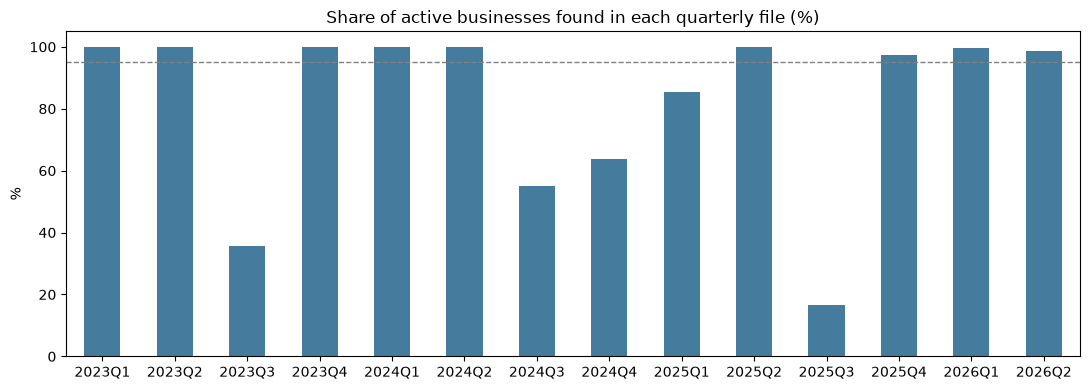

,checked against,records in the file,businesses checked,found in the file
quarter,,,,
2023Q1,2023Q2,1327028,891699,100.0
2023Q2,2023Q3,1341069,331778,100.0
2023Q3,2023Q4,357491,917131,35.8
2023Q4,2024Q1,1399410,954914,100.0
2024Q1,2024Q2,1453879,984041,100.0
2024Q2,2024Q3,1511902,446585,100.0
2024Q3,2024Q4,490543,654306,54.9
2024Q4,2025Q1,1171458,972513,63.7
2025Q1,2025Q2,1064181,1212200,85.4


In [14]:
main_only = mc.loc[(mc['registration_type'] == MAIN) & mc['registration_number'].notna(), ['snapshot_quarter', 'registration_number', 'founding_date']]
main_day = pd.to_datetime(main_only['founding_date'].str[:10], errors='coerce')
numbers = {q: set(g) for q, g in main_only.groupby('snapshot_quarter', observed=True)['registration_number']}
rows = []
for earlier, later in zip(QUARTERS, QUARTERS[1:]):
    end = pd.Period(earlier, 'Q').end_time.normalize()
    later_rows = main_only[(main_only['snapshot_quarter'] == later) & (main_day <= end)]
    found = later_rows['registration_number'].isin(numbers[earlier])
    rows.append({'quarter': earlier, 'checked against': later, 'records in the file': int((mc['snapshot_quarter'] == earlier).sum()),
                 'businesses checked': len(later_rows), 'found in the file': round(100 * found.mean(), 1)})
completeness = pd.DataFrame(rows).set_index('quarter')
completeness.to_csv(FIGURES / '01_A11_quarter_completeness.csv', encoding='utf-8-sig')

ax = completeness['found in the file'].plot.bar(title='Share of active businesses found in each quarterly file (%)', color='#457b9d', rot=0)
ax.axhline(95, color='grey', linestyle='--', linewidth=1)
ax.set_ylabel('%'); ax.set_xlabel(''); plt.tight_layout()
for extension in ['svg', 'png']:
    plt.savefig(FIGURES / f'01_A11_quarter_completeness.{extension}', dpi=300)
plt.show()
del main_only, main_day, numbers
completeness

**Result.** The files of 2023 Q1, 2023 Q2, 2023 Q4, 2024 Q1, 2024 Q2 and 2025 Q2 contain all, or all but a few, of the active
businesses (100.0%), and those of 2025 Q4 to 2026 Q2 between 97.3% and 99.7%. Five files are incomplete: 2023 Q3
contains 35.8% of the active businesses, 2024 Q3 54.9%, 2024 Q4 63.7%, 2025 Q1 85.4% and 2025 Q3 16.5%. For 2025 Q3,
the share is also low because the 109,541 records of part 1 have no registration number and cannot be matched
here; their number is recovered in Notebook 02 (section 4.1). The last quarter, 2026 Q3, has no later file to be
checked against.

**Interpretation.** Five quarterly files miss a large part of the active businesses. If they were used as they are, these businesses
would look closed in those quarters, and many would wrongly be recorded as failed.

**How preprocessing resolves it.** A registration cannot be missing from the register and then return unless it was
suspended (Commercial Register Law, Article 15). So, in Notebook 02 (section 5.1), a business that is present in the
complete file **before** an incomplete quarter and in the complete file **after** it is counted as active during the
incomplete quarter. This fills the gaps of the five incomplete files with the businesses that were certainly active.
It cannot recover a business that was founded and closed inside an incomplete quarter, because that business never
appears in any file.

In [15]:
del mc, day, capital, quarter_end, ids, id_format
import gc
gc.collect();

## Part B. Economic Datasets

### B1. Gross Domestic Product by Economic Activity (GASTAT)

This cell reports the period and economic activities covered, and checks for duplicate observations and
non-numeric values.

Columns: ['Quarter ID', 'Quarter', 'Economic Activity Section ID', 'Economic Activity Section', 'GDP'] | records: 792
Non-numeric values: 0
Period: 2010-Q1 to 2026-Q2 (66 quarters)
Duplicate activity and quarter: 0 

Economic Activity Section ID  Economic Activity Section                          
1                             Agriculture, Forestry & Fishing                        66
10                            Government Services                                    66
11                            Net Taxes on Products                                  66
12                            Gross Domestic Product                                 66
2                             Mining & Quarrying                                     66
3                             Manufacturing                                          66
4                             Electricity, Gas and Water                             66
5                             Construction                                           

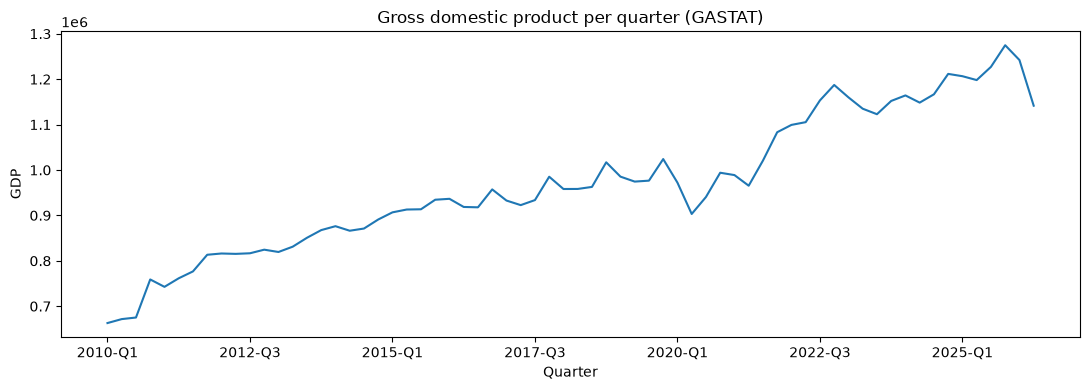

In [16]:
gdp = pd.read_parquet(RAW_DIR / 'gastat' / 'gastat_gdp_2026-10-21T09_14_09.657Z.csv.parquet')
gdp_value = pd.to_numeric(gdp['GDP'], errors='coerce')
print('Columns:', list(gdp.columns), '| records:', len(gdp))
print('Non-numeric values:', int((gdp['GDP'].notna() & gdp_value.isna()).sum()))
print('Period:', gdp['Quarter'].min(), 'to', gdp['Quarter'].max(), f'({gdp["Quarter"].nunique()} quarters)')
print('Duplicate activity and quarter:', int(gdp.duplicated(['Quarter ID', 'Economic Activity Section ID']).sum()), '\n')
print(gdp.groupby(['Economic Activity Section ID', 'Economic Activity Section']).size().rename('quarters').to_string())

total = gdp[gdp['Economic Activity Section'] == 'Gross Domestic Product'].assign(value=gdp_value)
ax = total.set_index('Quarter')['value'].plot(title='Gross domestic product per quarter (GASTAT)')
ax.set_ylabel('GDP'); plt.tight_layout(); plt.show()

**Result.** The gross domestic product covers 66 quarters, from 2010 Q1 to 2026 Q2, for 10 economic activities, net
taxes and the total, with no missing, non-numeric or duplicate value.

**Interpretation.** The series is complete and can be used without correction.

### B2. Point-of-Sale Transactions by Economic Sector (SAMA, published on DataSaudi)

This cell reports the years and sectors covered, verifies that the sectors sum to the published national total
in every year for which a total is available, and compares the most recent year with the year before it.

In [17]:
pos_sector = pd.read_parquet(RAW_DIR / 'sama' / 'sama_pos_sectors_2026-11-15T19_39_54.944Z.csv.parquet')
for column in ['Number of Transactions', 'Sales']:
    pos_sector[column] = pd.to_numeric(pos_sector[column], errors='coerce')
is_total = pos_sector['Economic Sectors ID'] == 'TO'
sectors = pos_sector[~is_total]
print('Columns:', list(pos_sector.columns), '| records:', len(pos_sector))
print('Years:', sorted(pos_sector['Year'].unique()))
print('Non-numeric values:', int(pos_sector[['Number of Transactions', 'Sales']].isna().sum().sum()))
print('Duplicate sector and year:', int(pos_sector.duplicated(['Year', 'Economic Sectors ID']).sum()), '\n')
print(sectors.groupby(['Economic Sectors ID', 'Economic Sectors']).size().rename('years').to_string(), '\n')

by_year = sectors.groupby('Year')[['Number of Transactions', 'Sales']].sum()
published = pos_sector[is_total].set_index('Year')[['Number of Transactions', 'Sales']]
check = pd.DataFrame({'sectors per year': sectors.groupby('Year').size(),
                      'sum of sectors (sales)': by_year['Sales'],
                      'published total (sales)': published['Sales'].reindex(by_year.index)})
check['ratio'] = check['sum of sectors (sales)'] / check['published total (sales)']
check['change from previous year'] = check['sum of sectors (sales)'].pct_change()
check.style.format({'sum of sectors (sales)': '{:,.0f}', 'published total (sales)': '{:,.0f}', 'ratio': '{:.4f}',
                    'change from previous year': '{:+.1%}'})

Columns: ['Year', 'Economic Sectors ID', 'Economic Sectors', 'Number of Transactions', 'Sales'] | records: 108
Years: ['2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
Non-numeric values: 0
Duplicate sector and year: 0 

Economic Sectors ID  Economic Sectors                                                    
D                    Electricity, gas, steam and air conditioning supply                     10
F                    Construction                                                            10
G                    Wholesale and retail trade; repair of motor vehicles and motorcycles    10
H                    Transportation and storage                                              10
I                    Accommodation and food service activities                               10
J                    Information and communication                                           10
P                    Education                                                    

,sectors per year,sum of sectors (sales),published total (sales),ratio,change from previous year
Year,,,,,
2016,10,"182,748,679","182,748,679",1.0000,+nan%
2017,10,"200,467,827","200,467,827",1.0000,+9.7%
2018,10,"232,305,825","232,305,825",1.0000,+15.9%
2019,10,"287,794,256","287,794,256",1.0000,+23.9%
2020,10,"357,297,966","357,297,966",1.0000,+24.2%
2021,10,"473,258,166","473,258,166",1.0000,+32.5%
2022,10,"559,134,945","559,134,945",1.0000,+18.1%
2023,10,"613,956,933","613,956,933",1.0000,+9.8%
2024,10,"671,719,009",nan,nan,+9.4%


**Result.** Point-of-sale transactions cover 10 ISIC sections in every year from 2016 to 2025. The sectors sum
exactly to the published national total in every year from 2016 to 2023 (ratio 1.0000); no total is published for
2024 and 2025. Sales grew by 9.4% in 2024 and 5.8% in 2025.

**Interpretation.** The sector figures are consistent with the official totals, and 2025 shows no break that would
suggest an incomplete year, so the national total of 2024 and 2025 can be computed from the sectors.

## Part C. Registered Economic Activities (Ministry of Commerce)

These files link each active commercial registration to the activities it registered, coded with the National
Classification of Economic Activities (SSIC) at three levels: section, class (four digits) and activity (six
digits). This cell reports, for each year, the number of activity records and registrations, the distribution of
registrations across sections, the number of activities per registration, and the share of registrations whose
activities fall in more than one section.

In [18]:
import glob
ACTIVITY_COLUMNS = ['الرقم الوطني', 'كود النشاط المستوى 1']
section_letter = dict(zip([str(i) for i in range(1, 22)], 'ABCDEFGHIJKLMNOPQRSTU'))
summary_rows, section_shares = [], {}
for year, pattern in [('2023', 'CR_ISISC_2023_PART*'), ('2024', 'CR_ISISC_2024_PART*'), ('2025', 'CR_ISIC_2025*')]:
    files = sorted(glob.glob(str(RAW_DIR / 'activity' / f'{pattern}.parquet')))
    table = pd.concat([pd.read_parquet(f, columns=ACTIVITY_COLUMNS) for f in files], ignore_index=True)
    table.columns = ['registration_number', 'section_code']
    table['section'] = table['section_code'].str.strip().map(section_letter)
    per_registration = table.groupby('registration_number')
    sections_per_registration = per_registration['section'].nunique()
    summary_rows.append({'year': year, 'files': len(files), 'activity records': len(table),
                         'registrations': table['registration_number'].nunique(),
                         'median activities per registration': per_registration.size().median(),
                         'registrations with more than one section': (sections_per_registration > 1).mean(),
                         'section code not recognised': int(table['section'].isna().sum())})
    section_shares[year] = table.drop_duplicates(['registration_number', 'section'])['section'].value_counts(normalize=True)
    del table, per_registration
    gc.collect()

activity_summary = pd.DataFrame(summary_rows).set_index('year')
print(activity_summary.to_string(formatters={'activity records': '{:,}'.format, 'registrations': '{:,}'.format,
                                             'registrations with more than one section': '{:.1%}'.format}))
print('\nShare of registrations with at least one activity in each section (%):')
print((pd.DataFrame(section_shares).sort_index() * 100).round(1).to_string())

      files activity records registrations  median activities per registration registrations with more than one section  section code not recognised
year                                                                                                                                                
2023     10        9,121,160     1,327,713                                 2.0                                    16.8%                            0
2024     13       12,047,491     1,563,648                                 2.0                                    17.4%                            0
2025      1       19,113,195     1,830,271                                 2.0                                    21.4%                            0

Share of registrations with at least one activity in each section (%):
         2023  2024  2025
section                  
A         0.7   1.0   1.1
B         0.5   0.5   0.5
C         8.5   8.5   9.4
D         0.2   0.2   0.3
E         0.8   0.8   0.9
F

**Result.** The registered activities cover 1,327,713 registrations in 2023, 1,563,648 in 2024 and 1,830,271 in
2025, with a median of two activities per registration. Between 16.8% and 21.4% of registrations have activities
in more than one section. Every section code is recognised. Trade (G) and construction (F) are the most common
sections.

**Interpretation.** These files provide the official activity of most active registrations. Because a registration
may have activities in several sections, a rule is needed to assign a single section to each registration.

## 3. Summary of Findings

| # | Finding | Section |
|---|---|---|
| 1 | The Ministry of Commerce records contain 19,749,510 rows across 15 quarters (2023 Q1 – 2026 Q3). | A2 |
| 2 | Three quarters are markedly smaller than their neighbours: 2023 Q3 (357,491 records), 2024 Q3 (490,543) and 2025 Q3 (338,896), against 1.1 – 1.9 million in the surrounding quarters. 2024 Q4 and 2025 Q1 are also smaller than the quarters around them. | A3 |
| 3 | Part 1 of 2025 Q3 (109,541 records) contains no identifier, registration type, legal form, region or e-commerce disclosure. | A1, A3, A4 |
| 4 | From 2025 Q4, the entity type, the e-commerce disclosure and the link from a branch to its main registration are not reported, and a separate registration number appears. | A1, A4 |
| 5 | One row of 2026 Q2 reproduces the column titles: it appears as the value "نوع السجل" of the registration type, "الكيان القانوني" of the entity type, and a fourteenth value of the region. | A8 |
| 6 | Identifiers have 10 digits. Almost all start with 70; other leading digits appear from 2025 Q2, mainly in 2026 Q3. | A5 |
| 7 | Founding dates are complete. Between 107 and 150 dates per quarter cannot be interpreted from 2025 Q2 onwards, and one or two dates per quarter precede 1950. No date falls after the end of its quarter. | A6 |
| 8 | Registered capital is missing for 504,202 records (5.8% in most quarters up to 2024 Q2), zero for 10,773 and negative for 3,139. Among the main registrations of 2026 Q3, 66.0% have a capital of 5,000 SAR or less, and 2.9% above 1 million SAR. | A7 |
| 9 | From 2025 Q2, an unknown capital is written as −1, 0 or 1 SAR instead of being left empty: −1 is the only negative value, −1 and 0 never appear before 2025 Q2, and 1 SAR rises from at most 650 to up to 12,539 records per quarter. 95.1% of businesses keep the same capital in every quarter. | A7 |
| 10 | The number of distinct cities rises from about 245 per quarter up to 2025 Q1 to between 1,724 and 4,726 from 2025 Q2, indicating a change in how cities are recorded. | A8 |
| 11 | The number of distinct legal forms varies between 40 and 53 per quarter (13 in 2025 Q3). | A8 |
| 12 | The e-commerce disclosure is reported by every record up to 2025 Q2, by 67.7% of the records of 2025 Q3, and by none from 2025 Q4. | A9 |
| 13 | Up to 2025 Q2, every branch names the business it belongs to; from 2025 Q4 branches are still marked but no longer linked to their business, and 2025 Q3 contains a single branch row. | A10 |
| 14 | After the Commercial Register Law of 3 April 2025 stopped issuing branch registrations, 15,512 branches of 2025 Q2 became main registrations by 2025 Q4, keeping the founding date of the branch; 19,844 more did so by 2026 Q3. 2,215 main registrations of 2025 Q2 are recorded as branches in 2025 Q4, which the law no longer allows. | A10 |
| 15 | Five quarterly files are incomplete: 2023 Q3 contains 35.8% of the active businesses, 2024 Q3 54.9%, 2024 Q4 63.7%, 2025 Q1 85.4% and 2025 Q3 16.5%; the other files contain between 97.3% and 100%. | A11 |
| 16 | Gross domestic product covers 2010 Q1 – 2026 Q2 (66 quarters, 12 activity groups) with no missing, non-numeric or duplicate values. | B1 |
| 17 | Point-of-sale transactions by economic sector cover 2016 – 2025 for 10 ISIC sections (D, F, G, H, I, J, P, Q, R, S). The sectors sum exactly to the published national total in every year from 2016 to 2023; no national total is published for 2024 and 2025. Sales grew by 9.4% in 2024 and 5.8% in 2025, with no break suggesting an incomplete year. | B2 |
| 18 | The registered activities cover 1,327,713 registrations in 2023, 1,563,648 in 2024 and 1,830,271 in 2025, with a median of two activities per registration; between 16.8% and 21.4% of registrations have activities in more than one section. | C |